# 03 – Frozen Encoder
**Coursework Topic 6 – News Topic Classification (AG News)**

Freeze DistilBERT, chỉ train Classification Head.

```
Text → Tokenizer → DistilBERT (FROZEN) → Mean pooling → Head (TRAINED) → 4 lớp
```

In [12]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from src import models
from src.models import LABELS

## 1. Cấu hình
`QUICK_TEST = True` để chạy thử nhanh . Đổi thành `False` khi chạy chính thức 

In [13]:
QUICK_TEST = False

if QUICK_TEST:
    cfg = dict(train_size=5000, val_size=1000, test_size=1000)
else:
    cfg = dict(train_size=None, val_size=None, test_size=None)  # toàn bộ AG News

print(cfg)

{'train_size': None, 'val_size': None, 'test_size': None}


## 2. Chạy thí nghiệm
Gồm: load dữ liệu → freeze encoder → trích đặc trưng → train head → đánh giá → lưu metrics, predictions, checkpoint.

In [14]:
out = models.run_experiment(max_len=64, batch_size=64, head_epochs=20, lr=1e-3, seed=42, **cfg)

Device: cpu | backbone: distilbert-base-uncased
train/val/test = 108000/12000/7600


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Params: total=66,365,956 trainable=3,076 size=253.2 MB


train feats:   0%|          | 0/1688 [00:00<?, ?it/s]

val feats:   0%|          | 0/188 [00:00<?, ?it/s]

test feats:   0%|          | 0/119 [00:00<?, ?it/s]

Test: acc=0.9029 macroF1=0.9028 | train 1038.1s | infer 60.6s


## 3. Tham số và kích thước mô hình

In [15]:
row = out["row"]
print(f"Total params     : {row['total_params']:,}")
print(f"Trainable params : {row['trainable_params']:,}")
print(f"Model size       : {row['model_size_mb']:.1f} MB (checkpoint head: {row['checkpoint_size_mb']*1024:.1f} KB)")

Total params     : 66,365,956
Trainable params : 3,076
Model size       : 253.2 MB (checkpoint head: 14.2 KB)


## 4. Kết quả trên tập test

In [16]:
metrics = pd.read_csv("../results/metrics/frozen_encoder_metrics.csv")
metrics.T

,0
model,frozen_encoder
backbone,distilbert-base-uncased
accuracy,0.902895
precision_macro,0.902938
recall_macro,0.902895
f1_macro,0.902787
train_time_s,1038.145755
feature_extraction_time_s,1025.361406
head_train_time_s,12.784349
inference_time_s,60.591762


In [17]:
print(classification_report(out["y_true"], out["y_pred"], target_names=LABELS, digits=4))

              precision    recall  f1-score   support

       World     0.9148    0.8932    0.9039      1900
      Sports     0.9613    0.9805    0.9708      1900
    Business     0.8500    0.8737    0.8617      1900
    Sci/Tech     0.8857    0.8642    0.8748      1900

    accuracy                         0.9029      7600
   macro avg     0.9029    0.9029    0.9028      7600
weighted avg     0.9029    0.9029    0.9028      7600



## 5. Learning curve của head

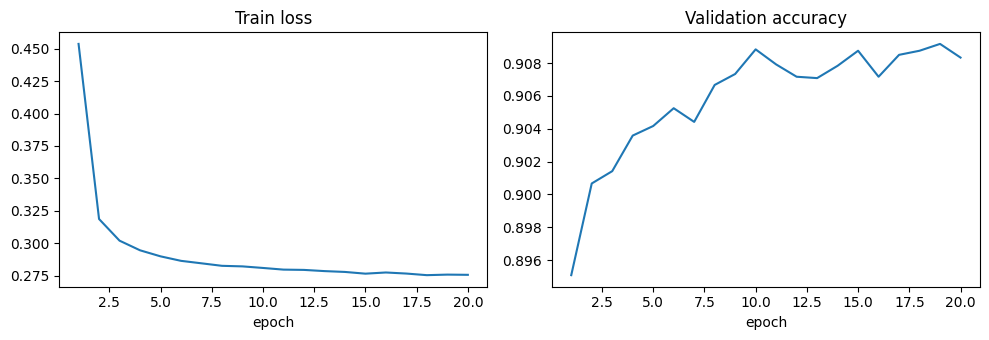

In [18]:
hist = pd.DataFrame(out["history"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist["epoch"], hist["train_loss"]); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist["epoch"], hist["val_accuracy"]); ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

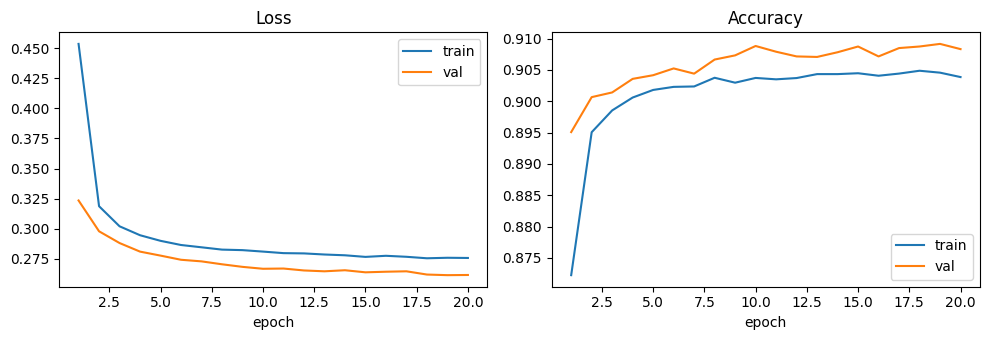

Epoch val tốt nhất: 19/20 | val acc 0.9092 | train acc 0.9046
Chênh train - val accuracy ở epoch tốt nhất: -0.46 điểm %


In [19]:
# Đường cong đầy đủ (train/val loss + accuracy) đọc từ file history do src/models.py lưu
from pathlib import Path
hp = Path("../results/metrics/frozen_encoder_history.csv")
if hp.exists():
    h = pd.read_csv(hp)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(h["epoch"], h["train_loss"], label="train"); ax[0].plot(h["epoch"], h["val_loss"], label="val")
    ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["epoch"], h["train_accuracy"], label="train"); ax[1].plot(h["epoch"], h["val_accuracy"], label="val")
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()
    best = h.loc[h["val_accuracy"].idxmax()]
    print(f"Epoch val tốt nhất: {int(best['epoch'])}/{len(h)} | val acc {best['val_accuracy']:.4f} | train acc {best['train_accuracy']:.4f}")
    print(f"Chênh train - val accuracy ở epoch tốt nhất: {(best['train_accuracy'] - best['val_accuracy']) * 100:+.2f} điểm %")
else:
    print("Chưa có frozen_encoder_history.csv -> chạy lại ô 'Chạy thí nghiệm' (đã được cập nhật để ghi history) rồi chạy lại ô này.")


### Training Monitoring → Decision (Frozen Encoder)
| Evidence | Interpretation | Decision |
|---|---|---|
| 20 epoch head, lr 1e-3; val accuracy tốt nhất 0,9104; test 0,9034 (chênh +0,70 điểm %, trong sai số ±0,6) | Checkpoint chọn theo validation không làm lệch test; head chỉ có 3.076 tham số nên khó overfit | Giữ checkpoint theo **val accuracy tốt nhất**; không chạm test khi chọn |
| Thấp hơn Baseline 1,7 điểm % (0,9034 so với 0,9204) | Nhiều khả năng do giới hạn của đặc trưng DistilBERT đóng băng, không phải do huấn luyện thiếu | **Không** tăng epoch/lr để "cứu" Frozen Encoder; so sánh trực tiếp với Fine-Tuning để trả lời câu hỏi nghiên cứu |

**Cách đọc đường cong ở ô trên:** nếu `train accuracy` gần bằng `val accuracy` và cả hai đều thấp → giới hạn do đặc trưng/đầu ra tuyến tính; nếu `val loss` tăng trong khi `train loss` giảm → overfit, dùng epoch sớm hơn. Chi tiết: `docs/results/decision_log.md` mục 2.


## 6. Confusion matrix 
Bản chính thức để lưu vào `results/figures/` do `src/evaluate.py` (Trúc Chi) tạo.

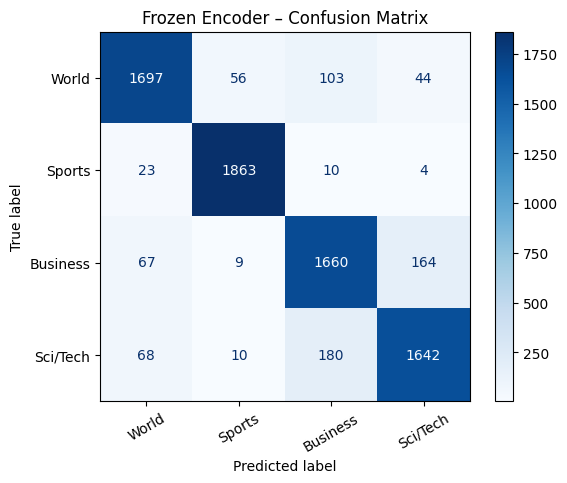

In [20]:
cm = confusion_matrix(out["y_true"], out["y_pred"])
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap="Blues", xticks_rotation=30)
plt.title("Frozen Encoder – Confusion Matrix"); plt.show()

## 7. Một vài mẫu dự đoán sai

In [21]:
preds = pd.read_csv("../results/metrics/frozen_encoder_predictions.csv")
wrong = preds[~preds["correct"]].sort_values("confidence", ascending=False)
print(f"Sai {len(wrong)}/{len(preds)} mẫu")
wrong[["text", "true_name", "pred_name", "confidence"]].head(10)

Sai 738/7600 mẫu


,text,true_name,pred_name,confidence
7539,Mars water tops science honours The discovery ...,World,Sci/Tech,0.997480
2574,Adobe updates RAW plug-in with digital negativ...,Business,Sci/Tech,0.996738
120,Oil prices bubble to record high The price of ...,World,Business,0.996320
5128,Argentina Basketball Coach Magnano Quits Ruben...,World,Sports,0.996239
2613,Embattled Mortgage Giant Agrees to Meet New St...,World,Business,0.995711
4359,Google 's New PC Search Tool Poses Risks NEW Y...,Business,Sci/Tech,0.995586
5886,Producer Price Surge Fuels Inflation Fears Pro...,World,Business,0.995565
6185,Special to ESPN.com It 's the age old question...,Business,Sports,0.995363
500,Iran shuts reformist websites WEBSITES CLOSE t...,Sci/Tech,World,0.994463
5129,Product Previews palmOneUpgrades Treo With Fas...,Business,Sci/Tech,0.994384


## 8. Thử dự đoán một câu

In [22]:
samples = ["Manchester United won the match 3-1.",
           "Apple unveils a new chip for its laptops.",
           "Stocks fell as oil prices surged on Tuesday."]
names, confs = models.predict_texts(out["model"], out["tokenizer"], samples, max_len=64)
for s, n, c in zip(samples, names, confs):
    print(f"{n:9s} ({c:.2f})  {s}")

Sports    (0.81)  Manchester United won the match 3-1.
Sci/Tech  (0.96)  Apple unveils a new chip for its laptops.
Business  (0.99)  Stocks fell as oil prices surged on Tuesday.
